# Khảo sát dữ liệu PhiUSIIL — Tuần 4

Phân loại nhị phân URL. Trong dữ liệu gốc, **0 = lừa đảo**, **1 = hợp lệ**. Notebook dùng dữ liệu CSV trong thư mục `data/` và chỉ phân tích chuỗi URL tại chỗ.

**Chạy lại trong VS Code:** chọn kernel Python 3.12 có `pandas`, `matplotlib`, `tldextract` và `ipykernel`, rồi chọn **Run All**.

[Nguồn UCI (CC BY 4.0)](https://archive.ics.uci.edu/dataset/967/phiusiil+phishing+url+dataset) · [Bài báo của tác giả](https://doi.org/10.1016/j.cose.2023.103545)

## 1. Đọc dữ liệu và kiểm tra nhãn

In [1]:
from pathlib import Path
import io
import ipaddress
import re
from urllib.parse import urlsplit

import matplotlib.pyplot as plt
import pandas as pd
import tldextract
from IPython.display import Image, Markdown, display

csv_path = Path("data/PhiUSIIL_Phishing_URL_Dataset.csv")
df = pd.read_csv(csv_path, dtype={"FILENAME": "string", "URL": "string", "Domain": "string",
                                 "TLD": "string", "Title": "string"}, keep_default_na=False, na_values=[""])
class_names = {0: "Lừa đảo", 1: "Hợp lệ"}
label_counts = df["label"].value_counts().reindex([0, 1], fill_value=0)
assert df.shape == (235795, 56)
assert label_counts.to_dict() == {0: 100945, 1: 134850}

print(f"Kích thước: {len(df):,} dòng × {df.shape[1]} cột")
labels = pd.DataFrame({"Lớp": pd.Series(class_names), "Số mẫu": label_counts,
                       "Tỷ lệ (%)": (label_counts / len(df) * 100).round(2)})
display(labels)

Kích thước: 235,795 dòng × 56 cột


,Lớp,Số mẫu,Tỷ lệ (%)
0,Lừa đảo,100945,42.81
1,Hợp lệ,134850,57.19


## 2. Từ điển dữ liệu

Bảng mô tả 56 cột theo tên gốc. Kiểu dữ liệu là kiểu quan sát khi đọc CSV bằng pandas. Các điểm và xác suất dẫn xuất được mô tả theo vai trò, công thức xem trong bài báo. Phạm vi đầu vào của đề tài là đặc trưng từ vựng và n-gram ký tự từ `URL`.

In [2]:
dictionary_source = """FILENAME|Định danh|Tên tệp gắn với bản ghi.
URL|URL|Chuỗi URL gốc.
URLLength|Từ vựng|Độ dài chuỗi URL.
Domain|Tên miền|Tên máy chủ hoặc địa chỉ IP trong dữ liệu.
DomainLength|Từ vựng|Độ dài giá trị tên miền.
IsDomainIP|Từ vựng|Chỉ báo tên máy chủ là địa chỉ IP.
TLD|Tên miền|Miền cấp cao nhất.
URLSimilarityIndex|Dẫn xuất|Điểm tương đồng URL của phương pháp PhiUSIIL.
CharContinuationRate|Dẫn xuất|Chỉ số về tính liên tiếp của ký tự trong URL.
TLDLegitimateProb|Dẫn xuất|Xác suất hợp lệ ước tính gắn với TLD.
URLCharProb|Dẫn xuất|Chỉ số xác suất dựa trên ký tự URL.
TLDLength|Từ vựng|Độ dài TLD.
NoOfSubDomain|Từ vựng|Số tên miền con theo cách đếm của bộ dữ liệu.
HasObfuscation|Từ vựng|Chỉ báo URL có dấu hiệu làm rối.
NoOfObfuscatedChar|Từ vựng|Số ký tự được làm rối.
ObfuscationRatio|Từ vựng|Tỷ lệ ký tự được làm rối.
NoOfLettersInURL|Từ vựng|Số chữ cái trong URL.
LetterRatioInURL|Từ vựng|Tỷ lệ chữ cái trong URL.
NoOfDegitsInURL|Từ vựng|Số chữ số trong URL.
DegitRatioInURL|Từ vựng|Tỷ lệ chữ số trong URL.
NoOfEqualsInURL|Từ vựng|Số dấu bằng trong URL.
NoOfQMarkInURL|Từ vựng|Số dấu hỏi trong URL.
NoOfAmpersandInURL|Từ vựng|Số dấu & trong URL.
NoOfOtherSpecialCharsInURL|Từ vựng|Số ký tự đặc biệt khác trong URL.
SpacialCharRatioInURL|Từ vựng|Tỷ lệ ký tự đặc biệt trong URL.
IsHTTPS|Từ vựng|Chỉ báo URL sử dụng HTTPS.
LineOfCode|Trang web|Số dòng mã nguồn trang.
LargestLineLength|Trang web|Độ dài dòng mã nguồn dài nhất.
HasTitle|Trang web|Chỉ báo trang có tiêu đề.
Title|Trang web|Nội dung tiêu đề trang.
DomainTitleMatchScore|Dẫn xuất|Điểm tương đồng giữa tên miền và tiêu đề trang.
URLTitleMatchScore|Dẫn xuất|Điểm tương đồng giữa URL và tiêu đề trang.
HasFavicon|Trang web|Chỉ báo trang có favicon.
Robots|Trang web|Chỉ báo liên quan đến khai báo robots của trang.
IsResponsive|Trang web|Chỉ báo trang có thiết kế thích ứng.
NoOfURLRedirect|Trang web|Số lần chuyển hướng URL.
NoOfSelfRedirect|Trang web|Số lần tự chuyển hướng.
HasDescription|Trang web|Chỉ báo trang có mô tả.
NoOfPopup|Trang web|Số cửa sổ bật lên.
NoOfiFrame|Trang web|Số iframe.
HasExternalFormSubmit|Trang web|Chỉ báo biểu mẫu gửi dữ liệu đến địa chỉ bên ngoài.
HasSocialNet|Trang web|Chỉ báo trang có liên kết mạng xã hội.
HasSubmitButton|Trang web|Chỉ báo trang có nút gửi biểu mẫu.
HasHiddenFields|Trang web|Chỉ báo trang có trường ẩn.
HasPasswordField|Trang web|Chỉ báo trang có trường mật khẩu.
Bank|Trang web|Chỉ báo nội dung liên quan đến ngân hàng.
Pay|Trang web|Chỉ báo nội dung liên quan đến thanh toán.
Crypto|Trang web|Chỉ báo nội dung liên quan đến tiền mã hóa.
HasCopyrightInfo|Trang web|Chỉ báo trang có thông tin bản quyền.
NoOfImage|Trang web|Số hình ảnh.
NoOfCSS|Trang web|Số tài nguyên CSS.
NoOfJS|Trang web|Số tài nguyên JavaScript.
NoOfSelfRef|Trang web|Số tham chiếu nội bộ.
NoOfEmptyRef|Trang web|Số tham chiếu rỗng.
NoOfExternalRef|Trang web|Số tham chiếu bên ngoài.
label|Nhãn|0 = lừa đảo, 1 = hợp lệ."""
dictionary = pd.DataFrame([row.split("|") for row in dictionary_source.splitlines()],
                          columns=["Cột", "Nhóm", "Ý nghĩa"])
assert dictionary["Cột"].tolist() == df.columns.tolist()
dictionary.insert(1, "Kiểu pandas", df.dtypes.astype(str).to_numpy())
with pd.option_context("display.max_rows", 60, "display.max_colwidth", None):
    display(dictionary)

,Cột,Kiểu pandas,Nhóm,Ý nghĩa
0,FILENAME,string,Định danh,Tên tệp gắn với bản ghi.
1,URL,string,URL,Chuỗi URL gốc.
2,URLLength,int64,Từ vựng,Độ dài chuỗi URL.
3,Domain,string,Tên miền,Tên máy chủ hoặc địa chỉ IP trong dữ liệu.
4,DomainLength,int64,Từ vựng,Độ dài giá trị tên miền.
5,IsDomainIP,int64,Từ vựng,Chỉ báo tên máy chủ là địa chỉ IP.
6,TLD,string,Tên miền,Miền cấp cao nhất.
7,URLSimilarityIndex,float64,Dẫn xuất,Điểm tương đồng URL của phương pháp PhiUSIIL.
8,CharContinuationRate,float64,Dẫn xuất,Chỉ số về tính liên tiếp của ký tự trong URL.
9,TLDLegitimateProb,float64,Dẫn xuất,Xác suất hợp lệ ước tính gắn với TLD.


## 3. Thống kê mô tả và phân bố theo lớp

Biểu đồ độ dài và số tên miền con dùng thang phần trăm trong từng lớp để so sánh hai lớp có số mẫu khác nhau. Giá trị độ dài từ 200 trở lên và số tên miền con từ 5 trở lên được gộp vào nhóm cuối của biểu đồ. Các thống kê bên dưới dùng dữ liệu gốc.

URLLength                    ...                     
             mean median    std min  ... median  std min  max
label                                ...                     
Lừa đảo     45.72   34.0  61.15  13  ...    3.0  5.0   1  499
Hợp lệ      26.23   26.0   4.82  15  ...    1.0  0.5   0    7

[2 rows x 15 columns]

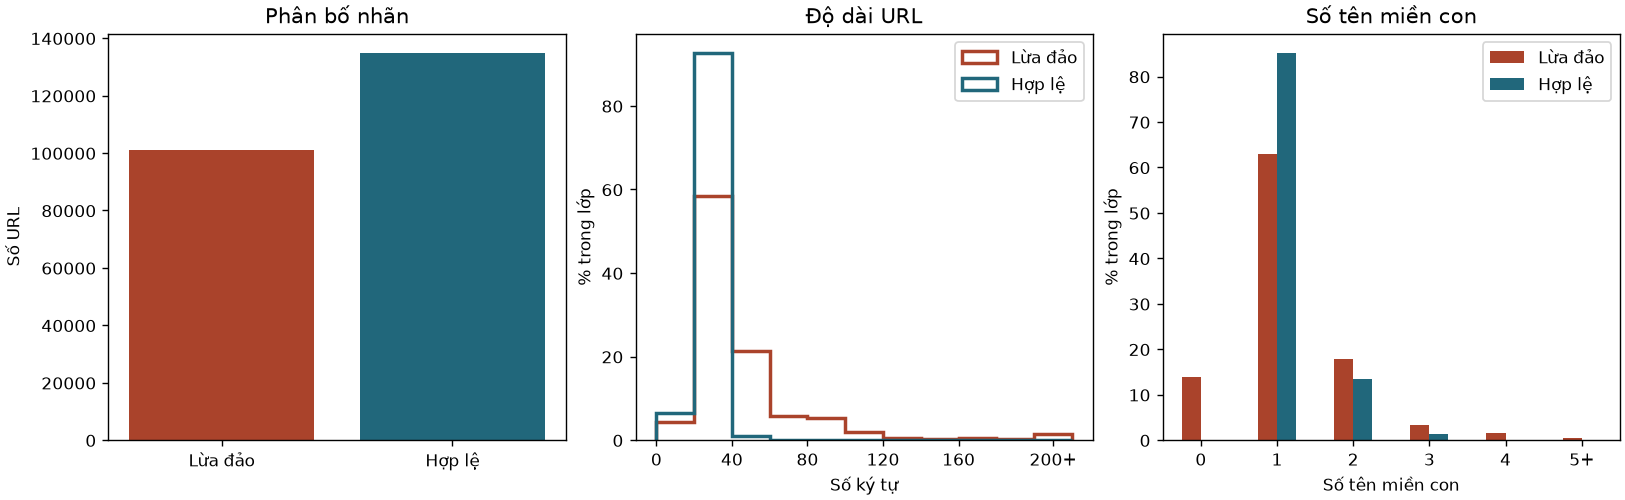

In [3]:
features = ["URLLength", "NoOfSubDomain", "NoOfOtherSpecialCharsInURL"]
summary = df.groupby("label")[features].agg(["mean", "median", "std", "min", "max"])
display(summary.rename(index=class_names).round(2))

colors = ["#aa432b", "#21677b"]
fig, axes = plt.subplots(1, 3, figsize=(13, 4), layout="constrained")
axes[0].bar(labels["Lớp"], labels["Số mẫu"], color=colors)
axes[0].set(title="Phân bố nhãn", ylabel="Số URL")

length_edges = list(range(0, 201, 20))
for label, name in class_names.items():
    lengths = df.loc[df["label"].eq(label), "URLLength"].clip(upper=200)
    axes[1].hist(lengths, bins=length_edges + [220], weights=[100 / len(lengths)] * len(lengths),
                 histtype="step", linewidth=2, label=name, color=colors[label])
axes[1].set(title="Độ dài URL", xlabel="Số ký tự", ylabel="% trong lớp",
            xticks=[0, 40, 80, 120, 160, 210], xticklabels=["0", "40", "80", "120", "160", "200+"])
axes[1].legend()

subdomains = pd.crosstab(df["NoOfSubDomain"].clip(upper=5), df["label"], normalize="columns") * 100
subdomains = subdomains.reindex(range(6), fill_value=0)
subdomains.rename(columns=class_names).plot.bar(ax=axes[2], color=colors, rot=0)
axes[2].set(title="Số tên miền con", xlabel="Số tên miền con", ylabel="% trong lớp",
            xticklabels=["0", "1", "2", "3", "4", "5+"])
axes[2].legend(title=None)
buffer = io.BytesIO()
fig.savefig(buffer, format="png", dpi=125)
plt.close(fig)
display(Image(data=buffer.getvalue()))

## 4. Quan hệ giữa đặc trưng và nhãn

Dùng tương quan hạng Spearman để mô tả quan hệ giữa các đặc trưng số và với chỉ báo phishing (1 nếu lừa đảo). Hệ số dương nghĩa là giá trị lớn hơn có xu hướng đi cùng nhãn lừa đảo trong bộ dữ liệu.

In [4]:
is_phishing = df["label"].eq(0).astype(int)
correlation = df[features].assign(IsPhishing=is_phishing).corr(method="spearman")
display(correlation.round(3))

medians = df.groupby("label")["URLLength"].median()
subdomain_rate = df["NoOfSubDomain"].ge(2).groupby(df["label"]).mean() * 100
special_rate = df["NoOfOtherSpecialCharsInURL"].gt(1).groupby(df["label"]).mean() * 100
display(Markdown(f"""
- **Phân bố nhãn.** URL hợp lệ chiếm {labels.loc[1, 'Tỷ lệ (%)']:.2f}% và URL lừa đảo chiếm {labels.loc[0, 'Tỷ lệ (%)']:.2f}%. Dùng Precision, Recall và F1 của lớp lừa đảo để theo dõi chất lượng phát hiện.
- **Độ dài.** Trung vị URL lừa đảo là {medians[0]:.0f} ký tự, so với {medians[1]:.0f} ký tự ở URL hợp lệ. Spearman với chỉ báo lừa đảo là {correlation.loc['URLLength', 'IsPhishing']:.3f}. Độ dài có thể hỗ trợ phân loại, và biểu đồ cho thấy mức độ chồng lấn giữa hai lớp.
- **Tên miền con.** {subdomain_rate[0]:.2f}% URL lừa đảo có từ hai tên miền con theo cách đếm của dữ liệu, so với {subdomain_rate[1]:.2f}% URL hợp lệ. Mức chênh lệch mô tả giá trị của đặc trưng này khi kết hợp với các đặc trưng khác.
- **Ký tự đặc biệt khác.** Tỷ lệ có hơn một ký tự thuộc nhóm `NoOfOtherSpecialCharsInURL` là {special_rate[0]:.2f}% với URL lừa đảo và {special_rate[1]:.2f}% với URL hợp lệ. Số lượng ký tự cho thấy khác biệt về cấu trúc chuỗi URL giữa hai lớp.
"""))

,URLLength,NoOfSubDomain,NoOfOtherSpecialCharsInURL,IsPhishing
URLLength,1.000,0.103,0.624,0.399
NoOfSubDomain,0.103,1.000,0.285,-0.033
NoOfOtherSpecialCharsInURL,0.624,0.285,1.000,0.613
IsPhishing,0.399,-0.033,0.613,1.000



- **Phân bố nhãn.** URL hợp lệ chiếm 57.19% và URL lừa đảo chiếm 42.81%. Dùng Precision, Recall và F1 của lớp lừa đảo để theo dõi chất lượng phát hiện.
- **Độ dài.** Trung vị URL lừa đảo là 34 ký tự, so với 26 ký tự ở URL hợp lệ. Spearman với chỉ báo lừa đảo là 0.399. Độ dài có thể hỗ trợ phân loại, và biểu đồ cho thấy mức độ chồng lấn giữa hai lớp.
- **Tên miền con.** 23.20% URL lừa đảo có từ hai tên miền con theo cách đếm của dữ liệu, so với 14.82% URL hợp lệ. Mức chênh lệch mô tả giá trị của đặc trưng này khi kết hợp với các đặc trưng khác.
- **Ký tự đặc biệt khác.** Tỷ lệ có hơn một ký tự thuộc nhóm `NoOfOtherSpecialCharsInURL` là 75.24% với URL lừa đảo và 21.38% với URL hợp lệ. Số lượng ký tự cho thấy khác biệt về cấu trúc chuỗi URL giữa hai lớp.


## 5. Chất lượng dữ liệu và nguy cơ rò rỉ

- Giá trị thiếu gồm ô trống và chuỗi chỉ chứa khoảng trắng. Mục URL sai định dạng kiểm tra cú pháp cơ bản của HTTP(S), tên máy chủ và cổng. Kiểm tra diễn ra tại chỗ, không kết nối tới các URL trong CSV.
- Ngoại lai dùng ngưỡng 1,5 × IQR theo từng đặc trưng trên toàn bộ bảng để mô tả. Cờ ngoại lai cần được xem xét trước khi xử lý vì giá trị hiếm có thể mang tín hiệu phân loại.
- Đếm nhóm tên miền đăng ký xuất hiện ở nhiều dòng, dùng danh sách hậu tố công cộng đi kèm `tldextract` (kể cả hậu tố riêng). Địa chỉ IP được nhóm theo IP, tên máy chủ ngoài danh sách hậu tố được nhóm theo tên đầy đủ. Mỗi nhóm phải nằm trọn trong một tập khi chia dữ liệu để đánh giá tên miền mới.

Khi Q1 = Q3, quy tắc IQR đánh dấu mọi giá trị khác mức này. Với đặc trưng rời rạc như số tên miền con, dùng thêm bảng phân bố theo lớp để diễn giải.

In [5]:
missing = df.isna().sum()
for column in df.select_dtypes(include=["string", "object"]):
    missing[column] += int(df[column].str.fullmatch(r"\s+", na=False).sum())

def get_valid_host(value):
    if pd.isna(value) or any(char.isspace() or ord(char) < 32 for char in value):
        return None
    try:
        parts = urlsplit(value)
        if parts.scheme.lower() not in {"http", "https"} or not parts.hostname:
            return None
        _ = parts.port  # Kiểm tra cổng có đúng cú pháp và trong khoảng hợp lệ.
        host = parts.hostname.rstrip(".").lower()
        try:
            return str(ipaddress.ip_address(host))
        except ValueError:
            ascii_host = host.encode("idna").decode("ascii")
            valid_labels = all(re.fullmatch(r"[a-z0-9](?:[a-z0-9-]{0,61}[a-z0-9])?", label)
                               for label in ascii_host.split("."))
            return ascii_host if valid_labels and len(ascii_host) <= 253 else None
    except (ValueError, UnicodeError):
        return None

hosts = df["URL"].map(get_valid_host)
extract_domain = tldextract.TLDExtract(suffix_list_urls=(), include_psl_private_domains=True)
groups_by_host = {host: extract_domain(host).top_domain_under_public_suffix or host
                  for host in hosts.dropna().unique()}
groups = hosts.map(groups_by_host)
group_sizes = groups.value_counts()
repeated_groups = group_sizes[group_sizes.gt(1)]
mixed_groups = df["label"].groupby(groups).nunique().gt(1).sum()
label_per_url = df["label"].groupby(df["URL"].where(df["URL"].str.strip().ne(""))).nunique()

quality = pd.Series({
    "Ô thiếu hoặc chỉ có khoảng trắng": missing.sum(),
    "Cột có ít nhất một ô thiếu": missing.gt(0).sum(),
    "Bản ghi trùng hoàn toàn (dòng dư)": df.duplicated().sum(),
    "URL trùng chính xác (dòng dư, chỉ URL có cú pháp hợp lệ)":
        df.loc[hosts.notna(), "URL"].duplicated().sum(),
    "URL có cả hai nhãn": label_per_url.gt(1).sum(),
    "URL thiếu hoặc sai cú pháp HTTP(S)": hosts.isna().sum(),
    "Nhóm tên miền có từ hai bản ghi": len(repeated_groups),
    "Số bản ghi thuộc nhóm tên miền lặp": repeated_groups.sum(),
    "Nhóm tên miền có cả hai nhãn": mixed_groups,
}, name="Số lượng")
display(quality.to_frame())
if missing.gt(0).any():
    display(missing[missing.gt(0)].to_frame("Số ô thiếu"))

values = df[features]
q1, q3 = values.quantile(0.25), values.quantile(0.75)
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outside = values.lt(lower) | values.gt(upper)
display(pd.DataFrame({"Q1": q1, "Q3": q3, "Cận dưới": lower, "Cận trên": upper,
                      "Số dòng ngoài cận": outside.sum()}))
display(Markdown(
    f"Tỷ lệ lớp đa số trên lớp thiểu số là **{label_counts.max()/label_counts.min():.2f}:1**. "
    f"Có **{len(repeated_groups):,}** nhóm tên miền lặp, gồm **{repeated_groups.sum():,}** bản ghi. "
    "Nếu chia ngẫu nhiên theo dòng, các URL cùng nhóm có thể xuất hiện ở cả tập huấn luyện và tập kiểm tra. "
    "Các cột xác suất như `TLDLegitimateProb` cần xem xét nguồn tính trước khi dùng vì chúng có thể "
    "được ước tính từ dữ liệu có nhãn. Phương án đã thống nhất chỉ trích xuất đặc trưng từ chuỗi URL."
))

,Số lượng
Ô thiếu hoặc chỉ có khoảng trắng,0
Cột có ít nhất một ô thiếu,0
Bản ghi trùng hoàn toàn (dòng dư),0
"URL trùng chính xác (dòng dư, chỉ URL có cú pháp hợp lệ)",425
URL có cả hai nhãn,0
URL thiếu hoặc sai cú pháp HTTP(S),0
Nhóm tên miền có từ hai bản ghi,7638
Số bản ghi thuộc nhóm tên miền lặp,45724
Nhóm tên miền có cả hai nhãn,106


,Q1,Q3,Cận dưới,Cận trên,Số dòng ngoài cận
URLLength,23.0,34.0,6.5,50.5,22493
NoOfSubDomain,1.0,1.0,1.0,1.0,57389
NoOfOtherSpecialCharsInURL,1.0,3.0,-2.0,6.0,12380


Tỷ lệ lớp đa số trên lớp thiểu số là **1.34:1**. Có **7,638** nhóm tên miền lặp, gồm **45,724** bản ghi. Nếu chia ngẫu nhiên theo dòng, các URL cùng nhóm có thể xuất hiện ở cả tập huấn luyện và tập kiểm tra. Các cột xác suất như `TLDLegitimateProb` cần xem xét nguồn tính trước khi dùng vì chúng có thể được ước tính từ dữ liệu có nhãn. Phương án đã thống nhất chỉ trích xuất đặc trưng từ chuỗi URL.

## Bước tiếp theo của tuần 4

Ghi rõ quyết định xử lý cho từng vấn đề và so sánh số liệu trước–sau. Chia dữ liệu theo nhóm tên miền trước khi khớp các phép biến đổi có học từ dữ liệu, chẳng hạn từ vựng n-gram. Notebook này là phần khảo sát và chẩn đoán.